<a href="https://colab.research.google.com/github/hodamalak/data-science-python-projects/blob/main/Fake_Reviews_Detection_Yelp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fake Reviews Detection - Yelp

In [ ]:
# variable to determine whether it should be run from scratch (in Google Colab)
run_from_scratch = True

if run_from_scratch:
  from google.colab import files
  import os
  #if you've already uploaded kaggle.json before, don't do it again
  if not(os.path.exists("kaggle.json")):
    files.upload() #upload kaggle.json
  !pip install --upgrade --force-reinstall --no-deps kaggle
  !mkdir -p ~/.kaggle
  !cp kaggle.json ~/.kaggle/
  !ls ~/.kaggle
  !chmod 600 /root/.kaggle/kaggle.json

  #Public Dataset
  print("\nGetting the first dataset...")
  dataset_url="ahmeddheyaa/yelpreviwsdb"
  dataset_name=dataset_url.split("/")[1]
  !kaggle datasets download -d  {dataset_url}
  !unzip -q {dataset_name}.zip
  !rm -f {dataset_name}.zip
  print("\tDone!\n")

  #Public Dataset
  print("Getting the second dataset...")
  dataset_url="ahmeddheyaa/prereviewscsv"
  dataset_name=dataset_url.split("/")[1]
  !kaggle datasets download -d  {dataset_url}
  !unzip -q {dataset_name}.zip
  !rm -f {dataset_name}.zip
  print("\tDone!")

  print("\nListing contents of current directory...")
  !ls

KeyboardInterrupt: ignored

In [ ]:
# import required libraries
import gc
import pandas as pd
import string

import gensim
import matplotlib.pyplot as plt
import nltk
import numpy as np
import seaborn as sns
import warnings
import xgboost as xgb

from gensim.models import Word2Vec
from nltk.corpus import stopwords
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize
from sklearn.datasets import make_multilabel_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve, RocCurveDisplay
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.multioutput import ClassifierChain
from sklearn.naive_bayes import ComplementNB
from wordcloud import WordCloud
from xgboost import to_graphviz, XGBClassifier
import plotly.express as px

In [ ]:
# notebook settings
warnings.filterwarnings("ignore")

In [ ]:
# Download necessary NLTK resources
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('vader_lexicon')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


True

In [ ]:
# Read the CSV file into a Pandas dataframe (load only sample/random 100,000 rows)
df = pd.read_csv('Reviews CSV.csv').sample(n=100000, random_state=42)

## Exploratory Data Analysis

In [ ]:
# preview top 5 rows
df.head(5)

,date,reviewID,reviewerID,reviewContent,rating,usefulCount,coolCount,funnyCount,flagged,restaurantID
775959,5/16/2010,Totyy2NPoiqx_PlU7yG5fQ,dWby_yHm46EK0PwDfiwD1g,Fantastic wine shop! The men and women who wo...,5,0,1,0,YR,8j-FMfOOYpB89BN3u8lvkQ
538609,1/2/2009,XfGEcg8MIrYx3BoB-TUQ1w,hRt2wwjavIswO-YEFi3siA,"Okay, this place reminds me of what Schuba's w...",4,1,0,0,YR,fGiQ5IqkiC_XnSJMCuq3ew
95729,5/27/2011,k_7RST-K3wTQU-PMVU_FUg,udzeDnj42U93futbIDKSLg,"Rich, sinful, delicious, chocolatey, did I say...",4,0,0,0,YR,ULEy88tbRkbwnDOOBdUCUQ
52430,12/25/2009,5LtKPk-B-4GG79ItheVoDw,TVIImqFRpu3PXihraZesDQ,Yuck. My sister made a reservation here for C...,2,1,0,3,N,d6UbRb9W5eA1yL-DuVZ8ug
292931,1/1/2012,fNRpgosYp6orWP3FZHZeNQ,byMsp_5HjRuA263SqsW57w,Started 2012 out by branching out and trying a...,5,1,0,0,NR,GYVuwj_L2AKVzw1UJ2waTw


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 100000 entries, 775959 to 669844
Data columns (total 10 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   date           100000 non-null  object
 1   reviewID       100000 non-null  object
 2   reviewerID     100000 non-null  object
 3   reviewContent  100000 non-null  object
 4   rating         100000 non-null  int64 
 5   usefulCount    100000 non-null  int64 
 6   coolCount      100000 non-null  int64 
 7   funnyCount     100000 non-null  int64 
 8   flagged        100000 non-null  object
 9   restaurantID   100000 non-null  object
dtypes: int64(4), object(6)
memory usage: 8.4+ MB


In [ ]:
df.shape

(100000, 10)

In [ ]:
df.isna().sum()

date             0
reviewID         0
reviewerID       0
reviewContent    0
rating           0
usefulCount      0
coolCount        0
funnyCount       0
flagged          0
restaurantID     0
dtype: int64

## Data Cleaning and Visualization

In [ ]:
# Replace null and NaN values in the flagged column with a default label
default_label = 'NR'
df['flagged'] = df['flagged'].fillna(default_label)
# Convert the flagged column to binary labels
df['label'] = df['flagged'].apply(lambda x: 1 if x == 'Y' else 0)

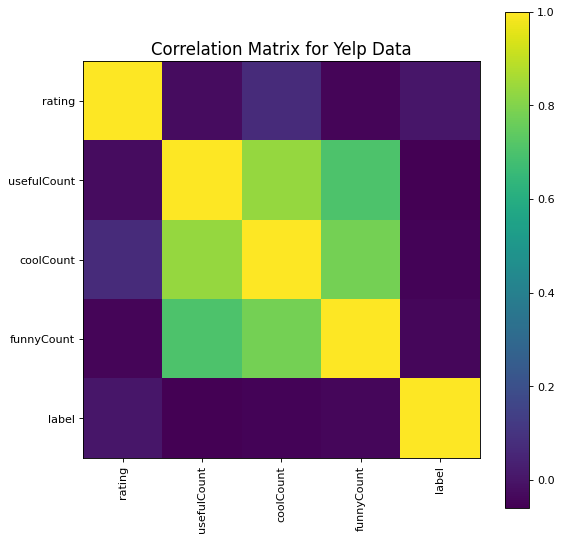

In [ ]:
def plotCorrelationMatrix(df, graphWidth):
    filename = 'Yelp Data'
    df = df.dropna('columns') # drop columns with NaN
    df = df[[col for col in df if df[col].nunique() > 1]] # keep columns where there are more than 1 unique values
    if df.shape[1] < 2:
        print(f'No correlation plots shown: The number of non-NaN or constant columns ({df.shape[1]}) is less than 2')
        return
    corr = df.corr()
    plt.figure(num=None, figsize=(graphWidth, graphWidth), dpi=80, facecolor='w', edgecolor='k')
    corrMat = plt.matshow(corr, fignum = 1)
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
    plt.yticks(range(len(corr.columns)), corr.columns)
    plt.gca().xaxis.tick_bottom()
    plt.colorbar(corrMat)
    plt.title(f'Correlation Matrix for {filename}', fontsize=15)
    plt.show()
plotCorrelationMatrix(df, 8)

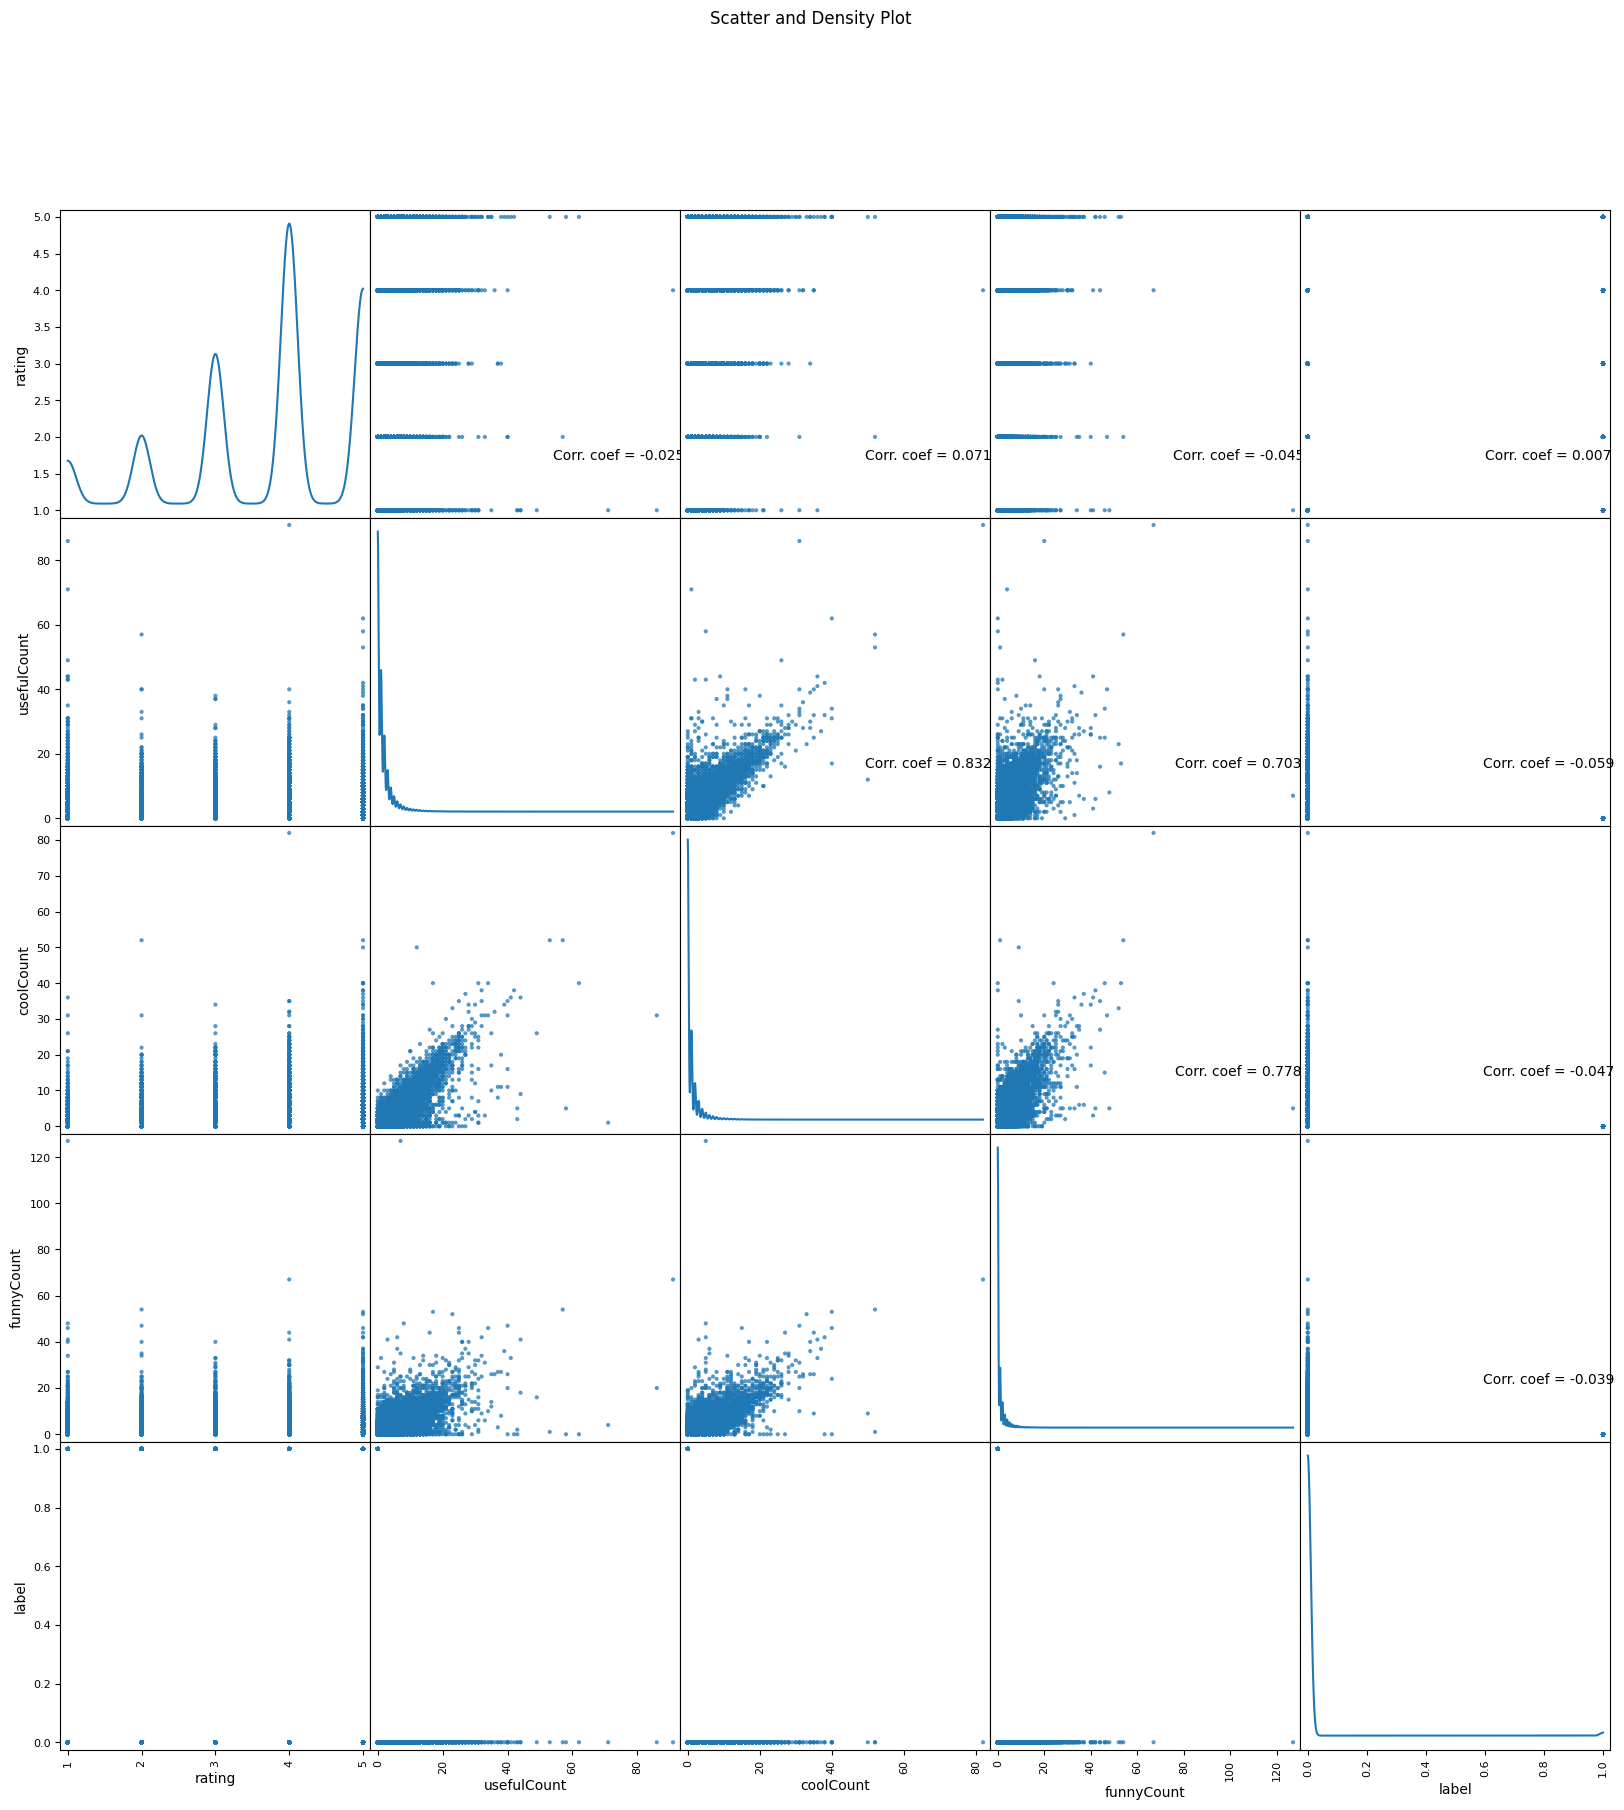

In [ ]:
def plotScatterMatrix(df, plotSize, textSize):
    df = df.select_dtypes(include =[np.number]) # keep only numerical columns
    # Remove rows and columns that would lead to df being singular
    df = df.dropna('columns')
    df = df[[col for col in df if df[col].nunique() > 1]] # keep columns where there are more than 1 unique values
    columnNames = list(df)
    if len(columnNames) > 10: # reduce the number of columns for matrix inversion of kernel density plots
        columnNames = columnNames[:10]
    df = df[columnNames]
    ax = pd.plotting.scatter_matrix(df, alpha=0.75, figsize=[plotSize, plotSize], diagonal='kde')
    corrs = df.corr().values
    for i, j in zip(*plt.np.triu_indices_from(ax, k = 1)):
        ax[i, j].annotate('Corr. coef = %.3f' % corrs[i, j], (0.8, 0.2), xycoords='axes fraction', ha='center', va='center', size=textSize)
    plt.suptitle('Scatter and Density Plot')
    plt.show()
plotScatterMatrix(df, 20, 10)

<Axes: xlabel='label', ylabel='rating'>

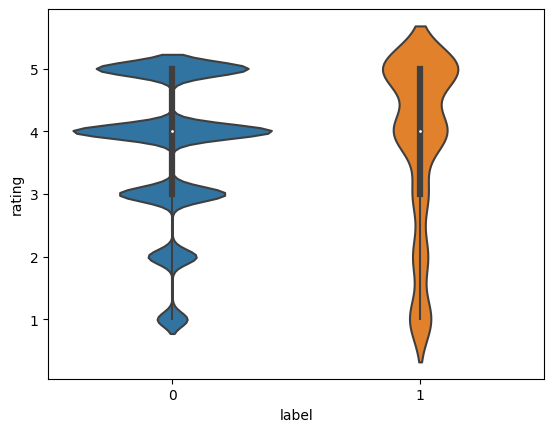

In [ ]:
sns.violinplot(x = df['label'], y = df['rating'])

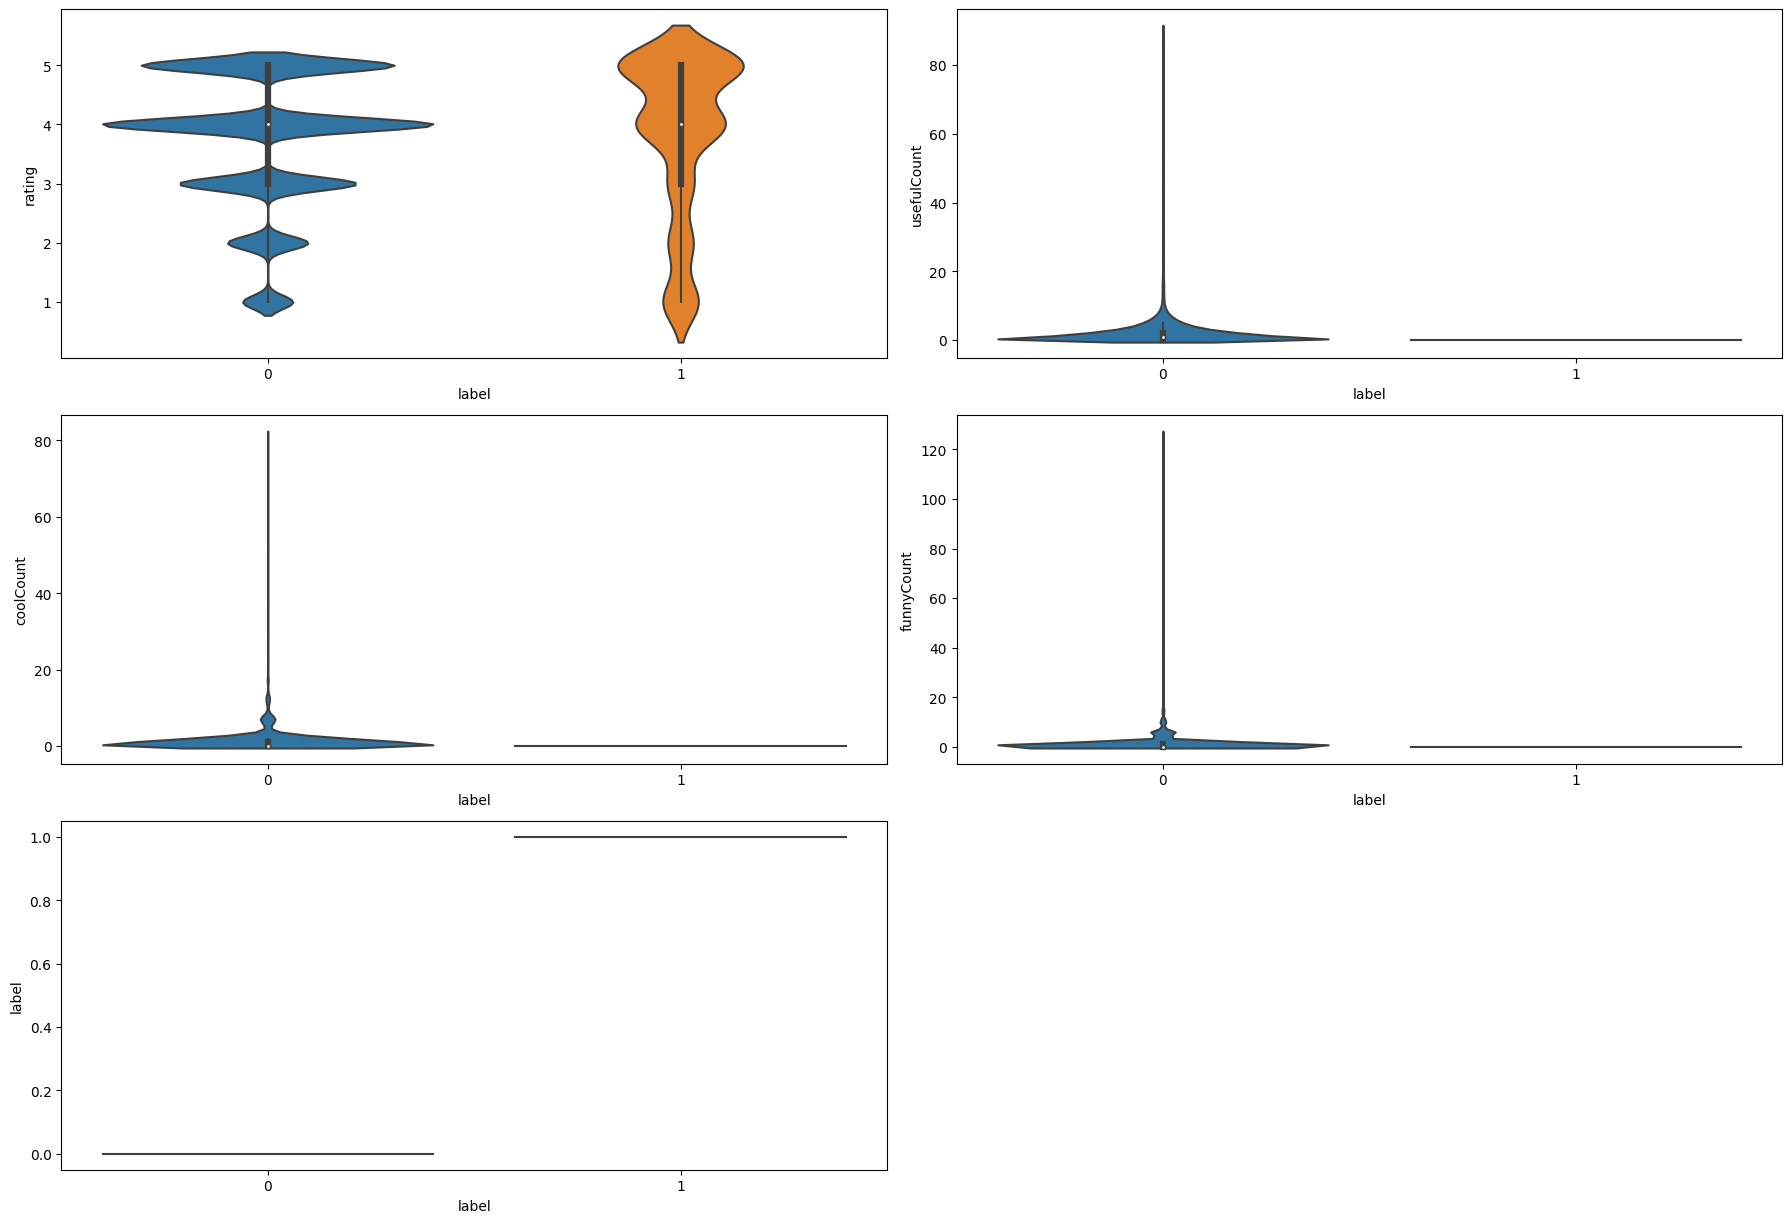

In [ ]:
num_cols = [colname for colname in df.columns if df[colname].dtype in ['int64','float64']]

#Numberical violin plots
fig3 = plt.figure(figsize = (18,20))
for index,i in enumerate(num_cols[:6]):
    plt.subplot(5,2,index+1)
    sns.violinplot(x = df['label'],y = df[i])
fig3.tight_layout(pad = 1.0)

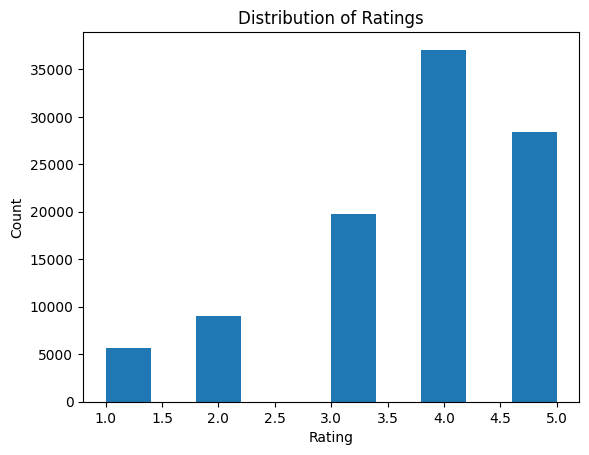

In [ ]:
plt.hist(df['rating'], bins=10)
plt.xlabel('Rating')
plt.ylabel('Count')
plt.title('Distribution of Ratings')
plt.show()

In [ ]:
df['date'].head()

775959     5/16/2010
538609      1/2/2009
95729      5/27/2011
52430     12/25/2009
292931      1/1/2012
Name: date, dtype: object

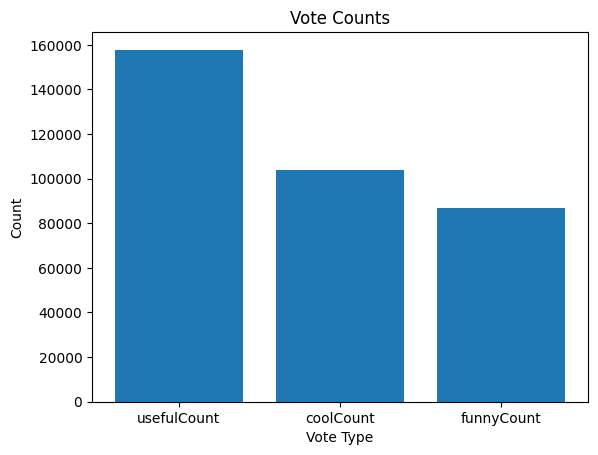

In [ ]:
counts = df[['usefulCount', 'coolCount', 'funnyCount']].sum()

plt.bar(counts.index, counts.values)
plt.xlabel('Vote Type')
plt.ylabel('Count')
plt.title('Vote Counts')
plt.show()

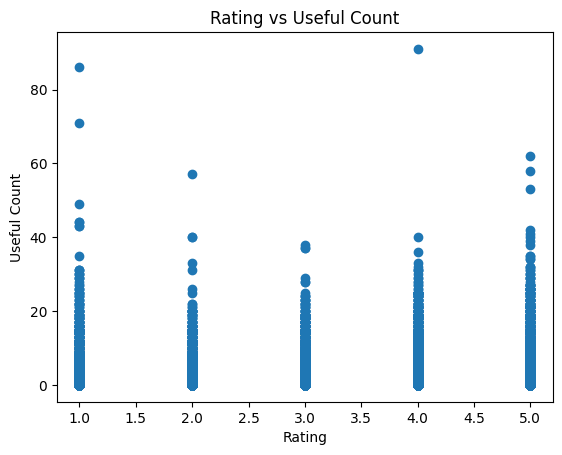

In [ ]:
plt.scatter(df['rating'], df['usefulCount'])
plt.xlabel('Rating')
plt.ylabel('Useful Count')
plt.title('Rating vs Useful Count')
plt.show()

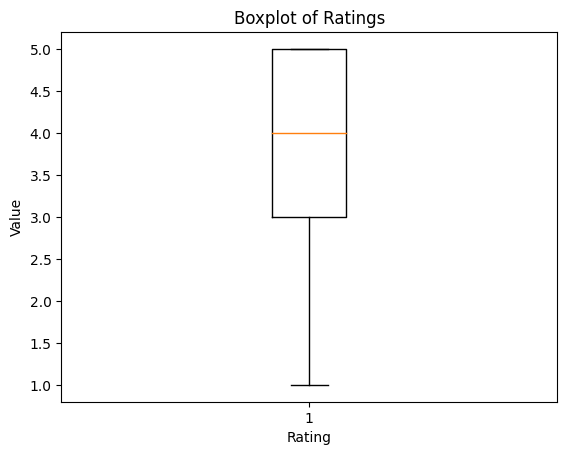

In [ ]:
plt.boxplot(df['rating'])
plt.xlabel('Rating')
plt.ylabel('Value')
plt.title('Boxplot of Ratings')
plt.show()

In [ ]:
#Function for Confusion matrix
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    thresh = cm.max() / 2.
    for i in range (cm.shape[0]):
        for j in range (cm.shape[1]):
            plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

In [ ]:
useful_reviews = len(df[df["usefulCount"]>0])
cool_reviews = len(df[df["coolCount"]>0])
funny_reviews = len(df[df["funnyCount"]>0])
negative_reviws = len(df[df["rating"]<2])
positive_reviews =len(df[df["rating"]>3])
total_reviews = len(df)

print("Total reviews: {}".format(total_reviews))
print("Useful reviews: {}".format(useful_reviews))
print("Funny reviews: {}".format(funny_reviews))
print("Cool reviews: {}".format(cool_reviews))
print("Total negative reviews: {}".format(negative_reviws))
print("Total positive reviews: {}".format(positive_reviews))

Total reviews: 100000
Useful reviews: 54689
Funny reviews: 31195
Cool reviews: 39385
Total negative reviews: 5672
Total positive reviews: 65510


In [ ]:
df = df.dropna(subset=['reviewContent'])
print("Total reviews after drop NA: {}".format(len(df['reviewContent'])))

Total reviews after drop NA: 100000


## Analysis

In [ ]:
# Create the TF-IDF vectorizer
vectorizer = TfidfVectorizer()
df['reviewContent'].fillna('', inplace=True)

# Fit the vectorizer to the documents and transform the documents into TF-IDF matrix
tfidf_matrix = vectorizer.fit_transform(df['reviewContent'])

# Get the feature names (terms)
feature_names = vectorizer.get_feature_names_out()

In [ ]:
def generate_bigrams(tokens):
    bigrams = []
    for i in range(len(tokens) - 1):
        bigram = (tokens[i], tokens[i + 1])
        bigrams.append(bigram)
    return bigrams

In [ ]:
# Initialize the sentiment analyzer
sia = SentimentIntensityAnalyzer()

# Calculate polarity for each text in the dataset
polarities = []
for text in df['reviewContent']:
    sentiment = sia.polarity_scores(text)
    polarity = sentiment['compound']  # compound score ranges from -1 to 1

    polarities.append(polarity)

In [ ]:
# Calculate overall polarity for the dataset
dataset_polarity = sum(polarities) / len(polarities)

print(f"Overall dataset polarity: {dataset_polarity}")

Overall dataset polarity: 0.7255512030000061


In [ ]:
df['Polarity']=polarities
df.head(5)

,date,reviewID,reviewerID,reviewContent,rating,usefulCount,coolCount,funnyCount,flagged,restaurantID,label,Polarity
775959,5/16/2010,Totyy2NPoiqx_PlU7yG5fQ,dWby_yHm46EK0PwDfiwD1g,Fantastic wine shop! The men and women who wo...,5,0,1,0,YR,8j-FMfOOYpB89BN3u8lvkQ,0,0.9776
538609,1/2/2009,XfGEcg8MIrYx3BoB-TUQ1w,hRt2wwjavIswO-YEFi3siA,"Okay, this place reminds me of what Schuba's w...",4,1,0,0,YR,fGiQ5IqkiC_XnSJMCuq3ew,0,0.7394
95729,5/27/2011,k_7RST-K3wTQU-PMVU_FUg,udzeDnj42U93futbIDKSLg,"Rich, sinful, delicious, chocolatey, did I say...",4,0,0,0,YR,ULEy88tbRkbwnDOOBdUCUQ,0,0.9889
52430,12/25/2009,5LtKPk-B-4GG79ItheVoDw,TVIImqFRpu3PXihraZesDQ,Yuck. My sister made a reservation here for C...,2,1,0,3,N,d6UbRb9W5eA1yL-DuVZ8ug,0,0.7725
292931,1/1/2012,fNRpgosYp6orWP3FZHZeNQ,byMsp_5HjRuA263SqsW57w,Started 2012 out by branching out and trying a...,5,1,0,0,NR,GYVuwj_L2AKVzw1UJ2waTw,0,0.9912


In [ ]:
# Define a function to preprocess the review text
def preprocess_text(text):
    # Convert the text to lowercase and split it into words
    words = text.lower().split()

    # Remove punctuation and numbers from the words
    words = [word.translate(str.maketrans('', '', string.punctuation + string.digits)) for word in words]

    # Remove stop words from the words
    stopwords = set(nltk.corpus.stopwords.words('english'))
    words = [word for word in words if word not in stopwords]

    # Stem the words using a Porter stemmer
    stemmer = PorterStemmer()
    words = [stemmer.stem(word) for word in words]

    # Return the preprocessed text as a list of words
    return ' '.join(words)
df['reviewContent'] = df['reviewContent'].apply(preprocess_text)

In [ ]:
# Train the Word2Vec model on the preprocessed review text
sentences = [review.split() for review in df['reviewContent']]
model = gensim.models.Word2Vec(sentences, vector_size=100, min_count=1, workers=4)

In [ ]:
gc.collect()

0

In [ ]:
doc_embeddings = []
for sentence in df['reviewContent']:
    words = sentence.split()
    vectors = [model.wv.get_vector(word) for word in words if word in model.wv.key_to_index]
    if vectors:
        mean_vector = np.mean(vectors, axis=0)
        doc_embeddings.append(mean_vector)
    else:
        doc_embeddings.append(np.zeros(model.vector_size))

# convert flagged column to binary labels
y = df['label']
df['doc_embeddings']=(doc_embeddings)

In [ ]:
df.head()

,date,reviewID,reviewerID,reviewContent,rating,usefulCount,coolCount,funnyCount,flagged,restaurantID,label,Polarity,doc_embeddings
775959,5/16/2010,Totyy2NPoiqx_PlU7yG5fQ,dWby_yHm46EK0PwDfiwD1g,fantast wine shop men women work realli know s...,5,0,1,0,YR,8j-FMfOOYpB89BN3u8lvkQ,0,0.9776,"[-0.22259903, -0.62801677, -0.81907195, -0.506..."
538609,1/2/2009,XfGEcg8MIrYx3BoB-TUQ1w,hRt2wwjavIswO-YEFi3siA,okay place remind schuba like douchbag start h...,4,1,0,0,YR,fGiQ5IqkiC_XnSJMCuq3ew,0,0.7394,"[-0.3319555, -0.064798385, -0.75100106, 0.0025..."
95729,5/27/2011,k_7RST-K3wTQU-PMVU_FUg,udzeDnj42U93futbIDKSLg,rich sin delici chocolatey say sinfulyup bit e...,4,0,0,0,YR,ULEy88tbRkbwnDOOBdUCUQ,0,0.9889,"[-0.010001096, -0.4462044, -0.29043913, -0.452..."
52430,12/25/2009,5LtKPk-B-4GG79ItheVoDw,TVIImqFRpu3PXihraZesDQ,yuck sister made reserv christma eve accid ass...,2,1,0,3,N,d6UbRb9W5eA1yL-DuVZ8ug,0,0.7725,"[-0.2559964, -0.15165955, -0.52470976, 0.16621..."
292931,1/1/2012,fNRpgosYp6orWP3FZHZeNQ,byMsp_5HjRuA263SqsW57w,start branch tri new thai deliveri search gru...,5,1,0,0,NR,GYVuwj_L2AKVzw1UJ2waTw,0,0.9912,"[-0.43074977, -0.36415416, -0.04045998, -0.520..."


In [ ]:
y = df['label']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(doc_embeddings, y, test_size=0.2, random_state=42)

In [ ]:
# Train a logistic regression model on the training data
clf = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)
clf.fit(X_train, y_train)

LogisticRegression(max_iter=1000, multi_class='multinomial')

In [ ]:
# Make predictions on the testing data and evaluate the model's accuracy
y_pred = clf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
confusion = confusion_matrix(y_test, y_pred)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99     19788
           1       0.00      0.00      0.00       212

    accuracy                           0.99     20000
   macro avg       0.49      0.50      0.50     20000
weighted avg       0.98      0.99      0.98     20000



Accuracy: 0.9892
Confusion matrix:
[[19784     4]
 [  212     0]]
Confusion matrix, without normalization


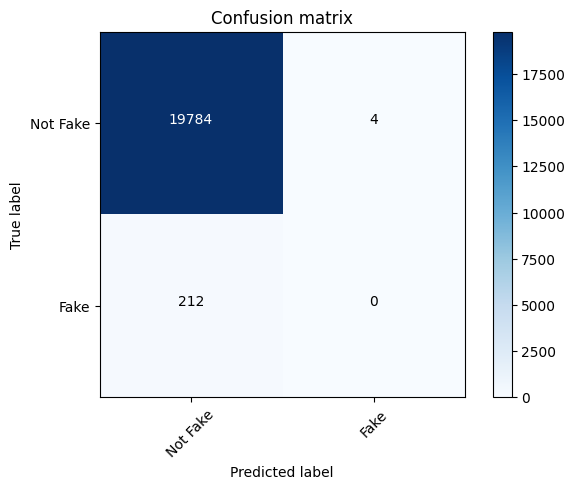

In [ ]:
print("Accuracy:", accuracy)

print("Confusion matrix:")
print(confusion)
plot_confusion_matrix(confusion, classes=['Not Fake','Fake'])

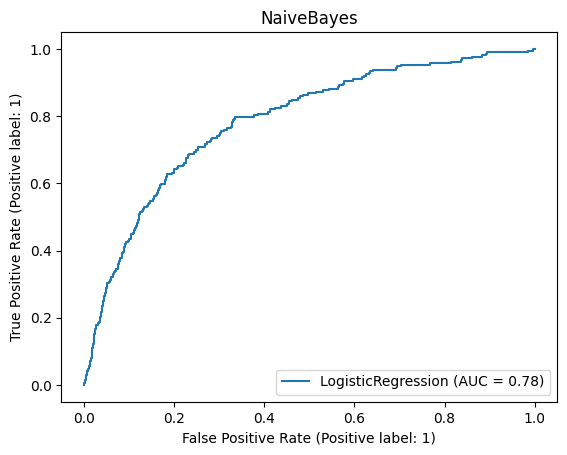

In [ ]:
# Plot the ROC curve
RocCurveDisplay.from_estimator(clf, X_test, y_test)
plt.title('NaiveBayes')
plt.show()


In [ ]:
xgb_model = xgb.XGBClassifier(max_depth = 2, use_label_encoder=False)
scores = cross_val_score(xgb_model,X_train,y_train,scoring = 'accuracy' )
mean_accuracy = np.mean(scores)

print(scores)
print(mean_accuracy)

[0.9895    0.9895625 0.9895    0.9894375 0.9895   ]
0.9894999999999999


In [ ]:
xgb_model.fit(X_train, y_train)
predictions = xgb_model.predict(X_test)

In [ ]:
# Calculate the accuracy score
accuracy = accuracy_score(y_test, predictions)
# Print the accuracy score
print("Accuracy:", accuracy)
print(classification_report(y_test, predictions))

Accuracy: 0.98935
              precision    recall  f1-score   support

           0       0.99      1.00      0.99     19788
           1       0.00      0.00      0.00       212

    accuracy                           0.99     20000
   macro avg       0.49      0.50      0.50     20000
weighted avg       0.98      0.99      0.98     20000



[[19787     1]
 [  212     0]]
Confusion matrix, without normalization


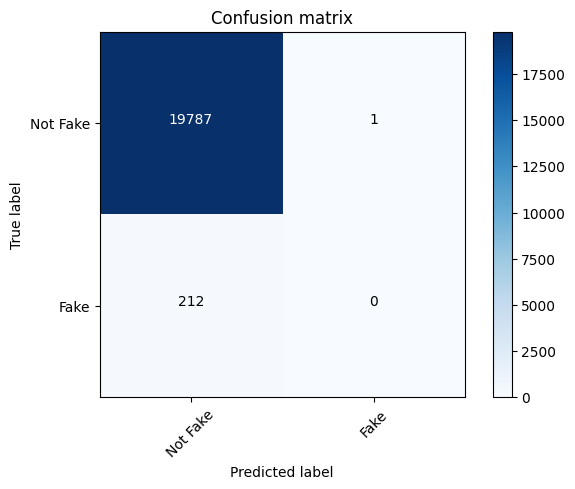

In [ ]:
# Compute the confusion matrix
cm = confusion_matrix(y_test, predictions)

# Print the confusion matrix
print(cm)
plot_confusion_matrix(cm, classes=['Not Fake','Fake'])

In [ ]:
num_features = len(xgb_model.feature_importances_)
print("Number of features used:", num_features)

Number of features used: 100


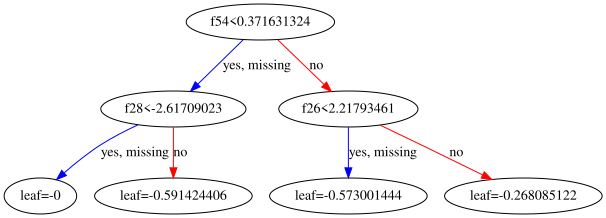

In [ ]:
to_graphviz(xgb_model)

In [ ]:
predictions_p = xgb_model.predict_proba(X_test)
XGBoostAUC = roc_auc_score(y_test.values, predictions_p[:,1])
XGBoostAUC

0.78062295235153

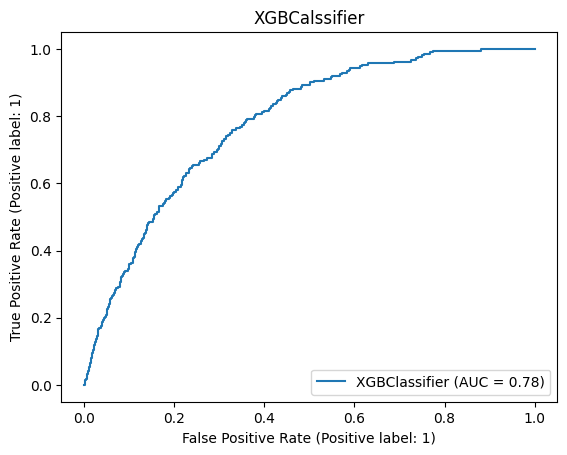

In [ ]:
# Plot the ROC curve
RocCurveDisplay.from_estimator(xgb_model, X_test, y_test)
plt.title('XGBCalssifier')
plt.show()

In [ ]:
# Initialize base classifiers
classifiers = [XGBClassifier(max_depth = 2, use_label_encoder=False),RandomForestClassifier()]

# Initialize the output predictions
y_train_predictions = []

# Iterate over the classifiers
for classifier in classifiers:
    # Fit the current classifier on the training data and predictions from previous classifiers
    classifier.fit(X_train, y_train)
    y_train_predictions.append(classifier.predict(X_train))
    # Update the training data with the predictions from previous classifiers
    y_train = y_train_predictions[-1]

# Predict using the last classifier in the chain
predictions = classifiers[-1].predict(X_test)

# Print the predictions
print(predictions)

[0 0 0 ... 0 0 0]


In [ ]:
def get_word2vec_embedding(text):
    # Tokenize the text
    words = word_tokenize(text)

    # Train a word2vec model on the tokenized words
    model = Word2Vec([words], min_count=1, vector_size=100)

    # Get the word2vec embeddings for the words
    embeddings = []
    for word in words:
        if word in model.wv:
            embeddings.append(model.wv[word])

    return embeddings

In [ ]:
new_comment="Here is an example comment"
pre_new_comment = preprocess_text(new_comment)
embeddings = get_word2vec_embedding(pre_new_comment)
# Predict the class label for the new record
predicted_class = classifiers[-1].predict(embeddings)
# Print the predicted class
print(predicted_class)

[0 0]


In [ ]:
# Calculate the accuracy score
accuracy = accuracy_score(y_test, predictions)
# Print the accuracy score
print(f"Accuracy: {accuracy} ({accuracy*100:.2f}%)")

Accuracy: 0.9894 (98.94%)


In [ ]:
print("Classfication Report:\n")
print(classification_report(y_test, predictions))

Classfication Report:

              precision    recall  f1-score   support

           0       0.99      1.00      0.99     19788
           1       0.00      0.00      0.00       212

    accuracy                           0.99     20000
   macro avg       0.49      0.50      0.50     20000
weighted avg       0.98      0.99      0.98     20000



In [ ]:
predictions_p = xgb_model.predict_proba(X_test)
ChainAUC = roc_auc_score(y_test.values, predictions_p[:,1])
ChainAUC

0.78062295235153

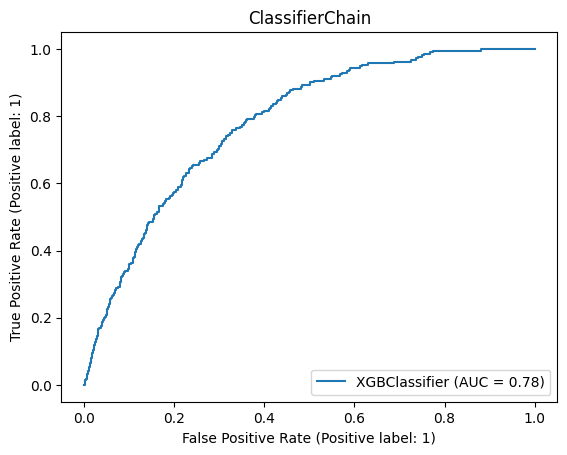

In [ ]:
# Plot the ROC curve
RocCurveDisplay.from_estimator(xgb_model, X_test, y_test)
plt.title('ClassifierChain')
plt.show()